# Galaxy cluster dataset: observational and classification audit

Run all cells from a fresh kernel with the project's Python environment (`pip install -e ".[analysis]"` from the package directory). No training or checkpoint is required. The JSON configuration controls the source experiment, catalogue, exports, caching, alignment and galleries. Source data and training caches are read-only.

The population is the **union of configured catalogue IDs and locally discovered RAW, CHANDRA and Legacy optical IDs**, before any split. It is not a claim of survey completeness. All catalogue-only objects remain visible. Directory labels, catalogue classifications and pipeline targets are distinct columns. Identical copies in several label directories are not independent observations.

Paths are resolved relative to the workspace containing `clusterprep` and `scratch`; the configuration can be changed below. `export=false` disables report exports; set `cache=false` too for a fully read-only interactive run. Full alignment can take several minutes; content-keyed analysis caches avoid repeating it.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "clusterprep/src/clusterprep").is_dir())
sys.path.insert(0, str(ROOT / "clusterprep/src"))
from clusterprep import dataset_analysis as da
CONFIG_PATH = ROOT / "clusterprep/configs/dataset_analysis.json"
config = da.read_config(CONFIG_PATH, ROOT)
# Interactive overrides, e.g. config.update(export=False, galleries=False).
report = da.Report(config)
display(pd.Series({k: config[k] for k in ("data_dir", "catalogue", "output_dir", "size", "alignment")}))

data_dir      /Users/antoinegdrn/PH_Project_I/scratch/data/P...
catalogue     /Users/antoinegdrn/PH_Project_I/scratch/data/P...
output_dir    /Users/antoinegdrn/PH_Project_I/outputs/datase...
size                                                        128
alignment                                                  True
dtype: object

## 1 — Dataset overview

Collect a complete manifest before applying task eligibility. The training inventory rejects conflicting duplicates and omits unsupported categories; this audit uses a tolerant discovery pass to retain and flag these objects, while reusing project FITS readers and target logic. Availability below means an unambiguous selected file, not successful image validation. Physical file presence is also recorded. CHANDRA discovery follows the existing `*CHANDRA.fits` convention. Other radio products are processing alternatives, not independent clusters; this notebook audits RAW, matching the configured experiment.

Metadata and pixel statistics are read once per unique content and modality. Multi-plane optical files produce one row per band. Non-singleton radio/X-ray cubes follow the project reader's first-plane convention; warnings are preserved in the diagnostics.

FITS metadata and pixels:   0%|          | 0/869 [00:00<?, ?it/s]

,Property,Value
0,Unique cluster IDs,304
1,Original annotations (excluding unclassified),273
2,radio selected file,304
3,xray selected file,115
4,optical selected file,273
5,Radio + X-ray,115
6,All three,115
7,Physical FITS copies,869
8,Unique products,692
9,Invalid/unreadable paths,0


,radio,xray,optical,clusters
0,True,False,False,31
1,True,False,True,158
2,True,True,True,115


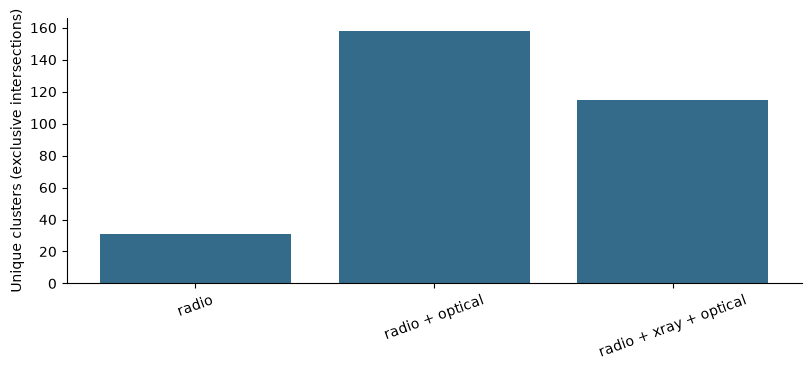

Configured geometry gives **24 variants per eligible training cluster**. This is a virtual dataset multiplier, not an observed sample count; no split is constructed here. Mixup, if enabled, is an on-the-fly training operation.

In [2]:
records, clusters, manifest, discovery_issues = da.inventory(config)
observations_all = da.collect_observations(manifest, config)
observations = da.unique_observations(observations_all)
for name, table in [("clusters", clusters), ("file_manifest", manifest),
                    ("fits_all_paths", observations_all), ("observations", observations)]:
    report.table(name, table)
composition = pd.DataFrame({"Property": ["Unique cluster IDs", "Original annotations (excluding unclassified)", *[m + " selected file" for m in da.MODALITIES],
                                         "Radio + X-ray", "All three", "Physical FITS copies", "Unique products", "Invalid/unreadable paths"],
    "Value": [len(clusters), clusters.has_annotation.sum(), *[clusters[m].sum() for m in da.MODALITIES],
              (clusters.radio & clusters.xray).sum(), clusters[list(da.MODALITIES)].all(axis=1).sum(), len(manifest),
              len(observations.drop_duplicates(["cluster_id", "modality", "sha256"])),
              observations_all.loc[observations_all.status != "ok", "path"].nunique()]})
display(report.table("dataset_composition", composition))
intersections = clusters.groupby(list(da.MODALITIES), dropna=False).size().rename("clusters").reset_index()
display(report.table("modality_intersections", intersections))
fig, ax = plt.subplots(figsize=(8, 3.5))
labels = intersections.apply(lambda r: " + ".join(m for m in da.MODALITIES if r[m]) or "No selected image", axis=1)
ax.bar(labels, intersections.clusters, color="#346b8a"); ax.set_ylabel("Unique clusters (exclusive intersections)")
ax.tick_params(axis="x", rotation=20)
report.figure("modality_intersections", fig)
zoom = config["experiment"].get("augmentation", {}).get("zoom")
variants = da.variant_count(zoom) if config["experiment"].get("augment", False) else 1
display(Markdown(f"Configured geometry gives **{variants} variants per eligible training cluster**. This is a virtual dataset multiplier, not an observed sample count; no split is constructed here. Mixup, if enabled, is an on-the-fly training operation."))

## 2 — Radio observations

Angular scales are projected WCS plane scales; width × scale is an approximate angular field of view, not an exact spherical footprint. Beam FWHM comes only from BMAJ/BMIN (degrees in FITS). Frequency is reported only from explicit frequency-axis coordinates, with their units; RESTFRQ is retained separately and is not assumed to be the observing frequency. Bandwidth is retained only when supplied in the header.

Pixel statistics describe the loaded image plane. Intensity plots separate BUNIT strings and optical bands: incompatible units are never pooled. They show **distributions of per-image quantiles**, not a pixel-weighted pooled histogram. The p99−p01 span is a robust intensity range, not a peak/noise dynamic range. No noise estimate is fabricated: a defensible source-free region or noise product is not specified. Representative radio images appear in Sections 7 and 9.

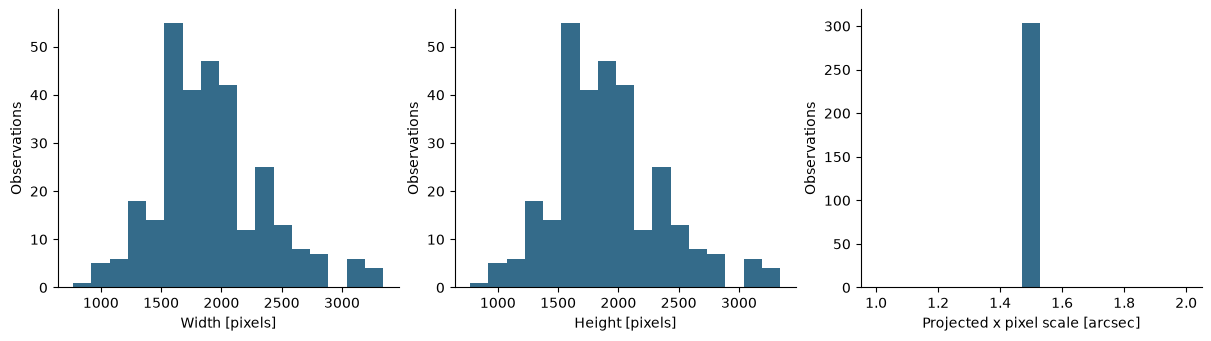

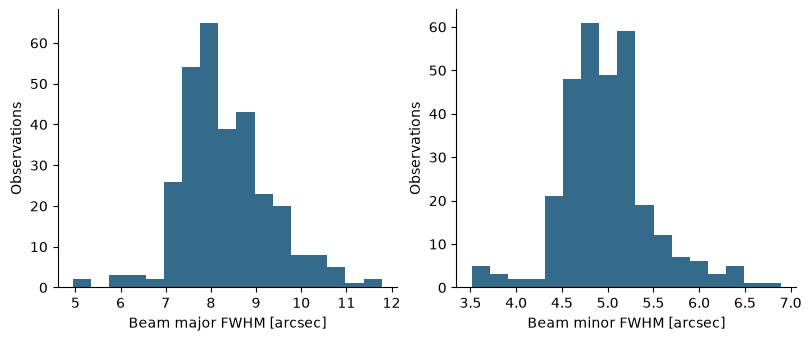

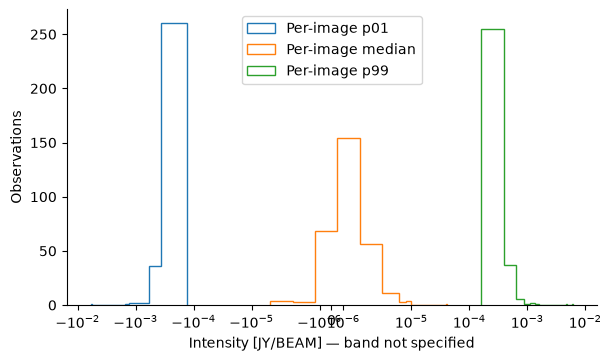

,modality,unit,band,width_count,width_median,width_min,width_max,height_count,height_median,height_min,...,fov_y_arcmin_min,fov_y_arcmin_max,finite_fraction_count,finite_fraction_median,finite_fraction_min,finite_fraction_max,p99_minus_p01_count,p99_minus_p01_median,p99_minus_p01_min,p99_minus_p01_max
0,optical,unknown,g,273,512.0,512,512,273,512.0,512,...,8.021333,85.229541,273,1.000000,1.000000,1.0,273,0.047033,0.000000,0.904305
1,optical,unknown,r,273,512.0,512,512,273,512.0,512,...,8.021333,85.229541,273,1.000000,1.000000,1.0,273,0.101257,0.000000,1.317282
2,optical,unknown,z,273,512.0,512,512,273,512.0,512,...,8.021333,85.229541,273,1.000000,1.000000,1.0,273,0.131742,0.000000,0.912188
3,radio,JY/BEAM,,304,1920.0,770,3342,304,1920.0,770,...,19.250000,83.550000,304,1.000000,1.000000,1.0,304,0.000540,0.000291,0.012071
4,xray,unknown,,115,1180.0,263,1483,115,1148.0,521,...,8.544400,37.121400,115,0.505965,0.363778,1.0,115,0.059995,0.006936,1.090548


In [3]:
da.observation_figures(observations, "radio", report)
characteristics = observations.loc[observations.status == "ok"].groupby(["modality", "unit", "band"], dropna=False)[
    ["width", "height", "pixel_x_arcsec", "pixel_y_arcsec", "fov_x_arcmin", "fov_y_arcmin", "finite_fraction", "p99_minus_p01"]].agg(["count", "median", "min", "max"])
characteristics.columns = ["_".join(c) for c in characteristics.columns]
display(report.table("observational_characteristics", characteristics.reset_index()))

## 3 — X-ray observations and partial coverage

CHANDRA values are not interpreted as physical flux. Exposure, energy bounds, units and product type are retained as header quantities; missing keys remain missing. Exposure histograms do not silently assume seconds when TIMEUNIT is absent.

Coverage below uses the **actual pipeline**: bilinear reprojection onto the cropped radio grid, footprint masking, finite-value block averaging, then a finite-value mask. A reduced pixel with any valid contribution is valid; this can increase the apparent support compared with native coverage. Missing CHANDRA is not assigned zero coverage. Zero overlap is retained as a measured zero. Alignment failures are listed rather than dropped silently. WCS overlap cannot establish astrophysical registration accuracy; contours support manual inspection.

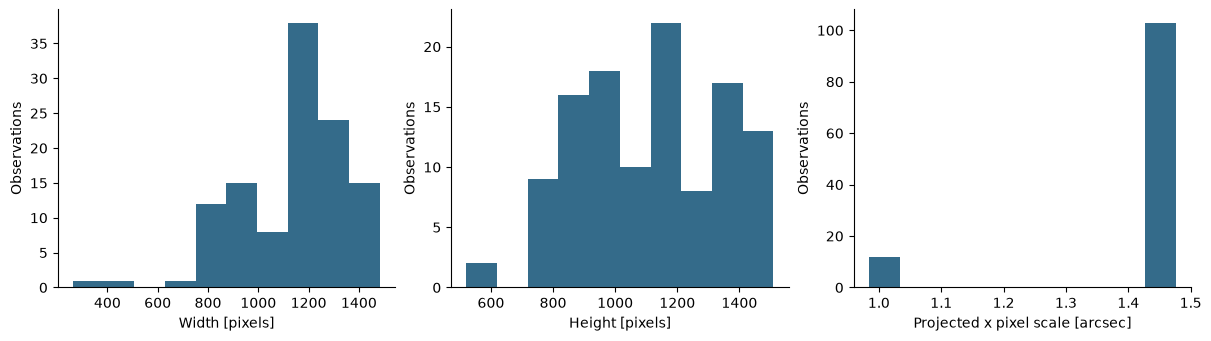

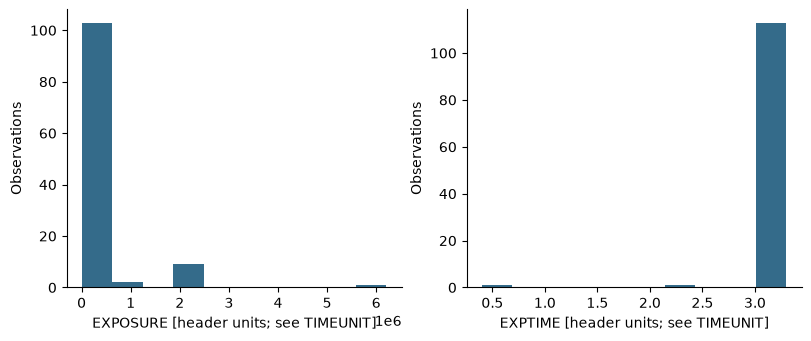

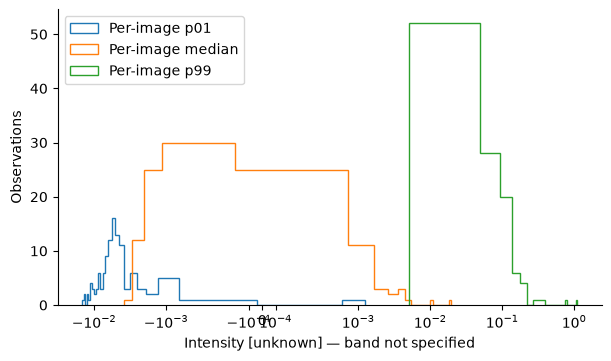

Pipeline preprocessing:   0%|          | 0/304 [00:00<?, ?it/s]

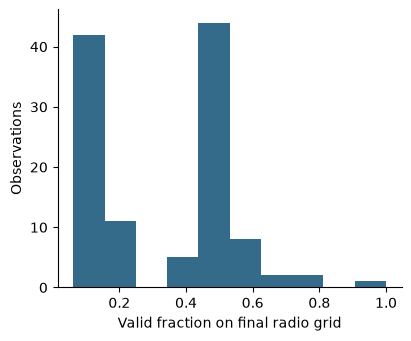

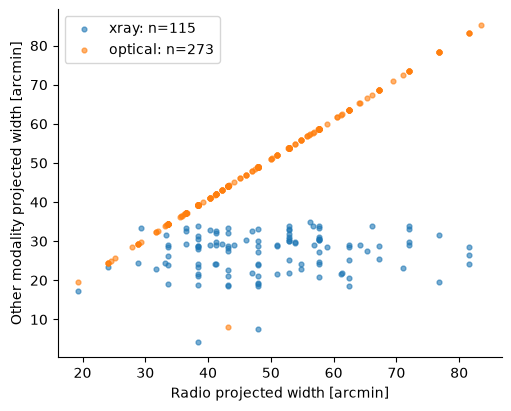

modality,cluster_id,optical,radio,xray
0,PSZ2G023.17+86.71,58.754862,57.60,30.6516
1,PSZ2G031.93+78.71,53.909227,52.85,21.9432
2,PSZ2G033.81+77.18,53.909228,52.85,33.0378
3,PSZ2G040.58+77.12,73.496532,72.05,33.9234
4,PSZ2G045.13+67.78,53.909241,52.85,NaN
...,...,...,...,...
299,PSZ2G199.75+46.59,39.219896,38.45,NaN
300,PSZ2G200.06+77.22,39.219902,38.45,NaN
301,PSZ2G202.66+66.98,44.116256,43.25,NaN
302,PSZ2G203.22+66.40,34.272617,33.60,NaN


In [4]:
da.observation_figures(observations, "xray", report)
alignment = da.collect_alignment(records, config)
report.table("preprocessing_statistics", alignment)
da_report_coverage = report.histograms("xray_valid_coverage", alignment, {"coverage": "Valid fraction on final radio grid"})
valid_obs = observations[observations.status == "ok"].drop_duplicates(["cluster_id", "modality"])
fov = valid_obs.pivot(index="cluster_id", columns="modality", values="fov_x_arcmin")
fig, ax = plt.subplots(figsize=(5, 4))
for modality in ("xray", "optical"):
    if "radio" in fov and modality in fov:
        paired = fov[["radio", modality]].dropna()
        ax.scatter(paired.radio, paired[modality], s=12, alpha=.6, label=f"{modality}: n={len(paired)}")
ax.set(xlabel="Radio projected width [arcmin]", ylabel="Other modality projected width [arcmin]")
if ax.collections: ax.legend()
report.figure("angular_coverage_comparison", fig)
report.table("angular_coverage", fov.reset_index())

## 4 — Optical observations

The configured experiment supports Legacy Survey FITS via the project's optional `legacy` modality, on the same radio grid. The configuration requests g/r/z; the audit inspects **all actual bands** and records BANDn, TELESCOP, INSTRUME and FILTER without inventing an instrument. The local filename convention and experiment identify the intended Legacy Survey role; header provenance is separately tabulated. No external downloads occur.

Optical data are optional CNN inputs, not annotations. The experiment requests training-set optical normalization. This unsplit EDA does **not** estimate training bounds or pretend to reproduce them: optical galleries use clearly labelled per-image display stretches only.

,cluster_id,path,band,status,telescope,instrument,unit
596,PSZ2G023.17+86.71,/Users/antoinegdrn/PH_Project_I/scratch/data/P...,g,ok,unknown,unknown,unknown
597,PSZ2G023.17+86.71,/Users/antoinegdrn/PH_Project_I/scratch/data/P...,r,ok,unknown,unknown,unknown
598,PSZ2G023.17+86.71,/Users/antoinegdrn/PH_Project_I/scratch/data/P...,z,ok,unknown,unknown,unknown
599,PSZ2G031.93+78.71,/Users/antoinegdrn/PH_Project_I/scratch/data/P...,g,ok,unknown,unknown,unknown
600,PSZ2G031.93+78.71,/Users/antoinegdrn/PH_Project_I/scratch/data/P...,r,ok,unknown,unknown,unknown
...,...,...,...,...,...,...,...
1410,PSZ2G203.22+66.40,/Users/antoinegdrn/PH_Project_I/scratch/data/P...,r,ok,unknown,unknown,unknown
1411,PSZ2G203.22+66.40,/Users/antoinegdrn/PH_Project_I/scratch/data/P...,z,ok,unknown,unknown,unknown
1412,PSZ2G205.90+73.76,/Users/antoinegdrn/PH_Project_I/scratch/data/P...,g,ok,unknown,unknown,unknown
1413,PSZ2G205.90+73.76,/Users/antoinegdrn/PH_Project_I/scratch/data/P...,r,ok,unknown,unknown,unknown


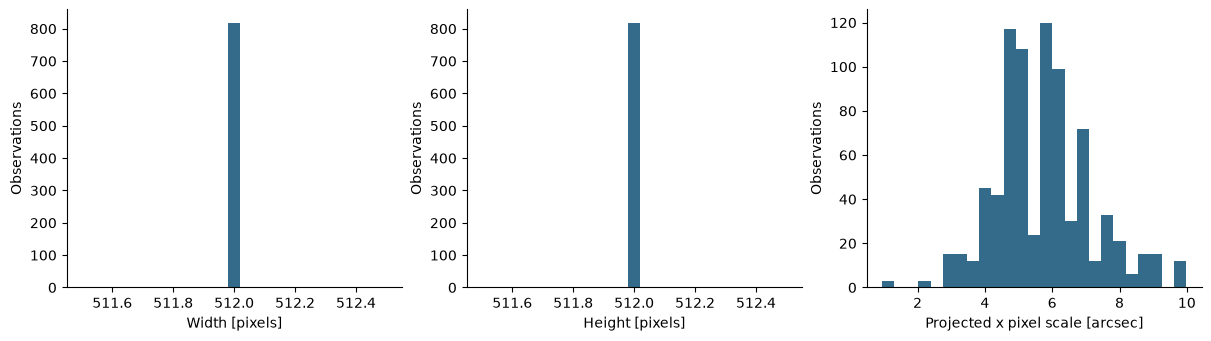

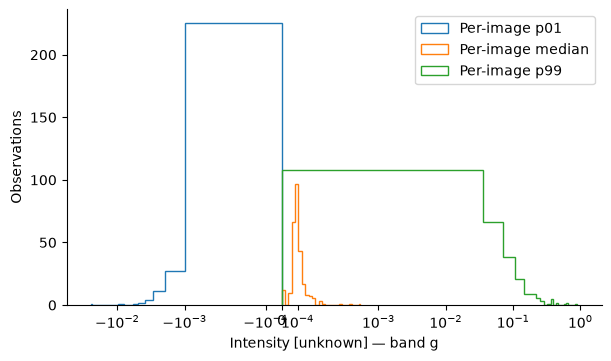

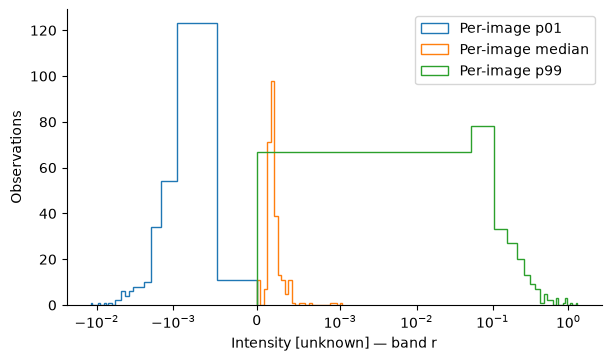

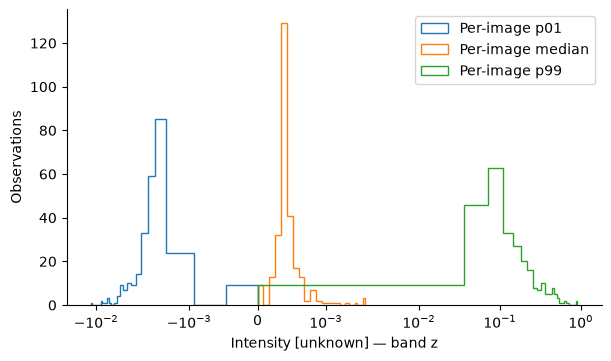

In [5]:
optical = observations[observations.modality == "optical"]
if optical.empty:
    display(Markdown("**No optical FITS found at the configured optical source location.**"))
else:
    display(report.table("optical_provenance", optical[["cluster_id", "path", "band", "status", "telescope", "instrument", "unit"]]))
    da.observation_figures(observations, "optical", report)

## 5 — Cluster metadata

Redshift and available physical quantities come from the configured source catalogue, joined by exact ID. Duplicate catalogue IDs are reported and the first row is used for descriptive plots. Catalogue classification strings are retained separately from directory labels. Negative/non-finite redshifts are unavailable for these plots. M500 and r500 are reported only as catalogue values, without assuming units or cosmology absent from the CSV.

RA/Dec below are **radio image-centre WCS coordinates**, not asserted cluster-centre measurements. They are explicitly labelled to avoid fabricating catalogue astrometry. Redshift differences are descriptive; a two-sample KS statistic compares disjoint with/without-X-ray subsets and does not prove selection causality.

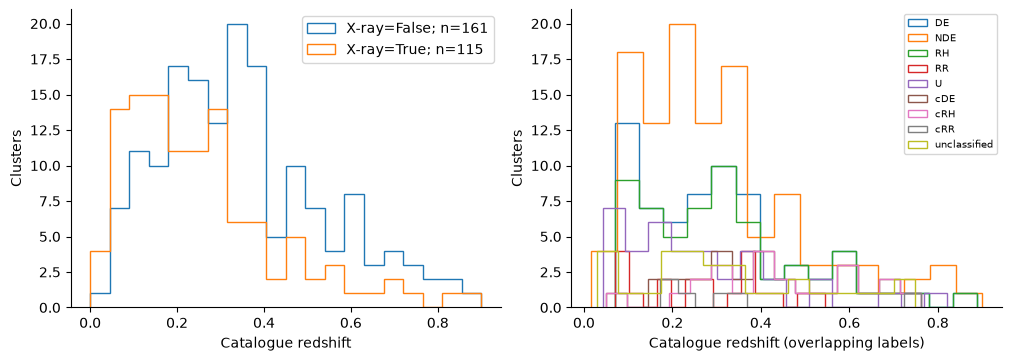

,n_with_xray,n_without_xray,KS,p_value
0,115,161,0.28323,0.000031


,quantity,count,mean,std,min,25%,50%,75%,max
0,z,276.0,0.310743,0.189434,0.016,0.16925,0.283,0.398,0.90
1,M500,276.0,4.874094,1.644890,1.120,3.76750,4.925,5.870,11.69
2,M500_err,276.0,0.470145,0.176909,0.110,0.33000,0.480,0.600,1.27
3,r500,276.0,1059.797101,104.844970,732.000,994.00000,1059.500,1113.250,1490.00
4,r500_err,276.0,34.909420,9.467405,10.000,28.00000,36.000,42.000,68.00


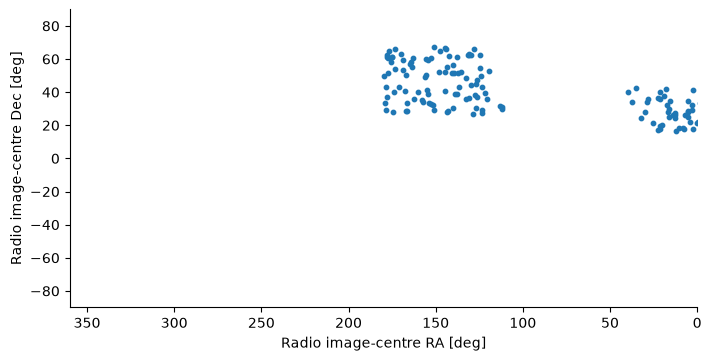

In [6]:
if "z" in clusters:
    zframe = clusters[clusters.z.notna() & (clusters.z >= 0)]
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
    for has_xray, group in zframe.groupby("xray"):
        axes[0].hist(group.z, bins=np.linspace(0, max(zframe.z.max(), .1), 21), histtype="step", label=f"X-ray={has_xray}; n={len(group)}")
    axes[0].set(xlabel="Catalogue redshift", ylabel="Clusters"); axes[0].legend()
    matrix = da.label_matrix(zframe)
    for label in matrix:
        values = zframe.loc[matrix[label].eq(1), "z"]
        if len(values): axes[1].hist(values, bins=15, histtype="step", label=label)
    axes[1].set(xlabel="Catalogue redshift (overlapping labels)", ylabel="Clusters"); axes[1].legend(fontsize=7)
    report.figure("redshift_distributions", fig)
    report.table("redshift_by_xray", zframe.groupby("xray").z.describe().reset_index())
    from scipy.stats import ks_2samp
    a, b = zframe.loc[zframe.xray, "z"], zframe.loc[~zframe.xray, "z"]
    if len(a) and len(b):
        ks = ks_2samp(a, b)
        display(report.table("redshift_subset_comparison", pd.DataFrame([dict(n_with_xray=len(a), n_without_xray=len(b), KS=ks.statistic, p_value=ks.pvalue)])))
metadata_columns = [c for c in ["z", "M500", "M500_err", "r500", "r500_err"] if c in clusters]
if metadata_columns:
    display(report.table("catalogue_statistics", clusters[metadata_columns].describe().T.rename_axis("quantity").reset_index()))
radio = valid_obs[valid_obs.modality == "radio"]
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.scatter(radio.image_center_ra_deg, radio.image_center_dec_deg, s=10)
ax.set(xlabel="Radio image-centre RA [deg]", ylabel="Radio image-centre Dec [deg]", xlim=(360, 0), ylim=(-90, 90))
report.figure("sky_positions", fig)

## 6 — Original annotations and classification targets

The current supported training vocabulary is DE, NDE, RR, RH, cRR, cRH. Directory labels cDE, U and unclassified are retained in this audit but do not by themselves confer task eligibility. Original labels may overlap. The catalogue has a separate classification field and may disagree with directory membership; both remain traceable.

All targets below call `task_target` directly on the training-supported labels. DE/NDE requires explicit DE or NDE; **DE=0, NDE=1** for the documented class order. Subtypes do not automatically create a DE target. For binary RR/RH tasks, candidate-positive treats candidates as positives for the corresponding subtype; candidate-ignore excludes an unconfirmed candidate of that target. For multilabel RR/RH, ignored candidates mask only the affected output, rather than excluding the cluster. DE-only objects are ineligible for subtype tasks. Non-target subtype annotations can become pipeline negatives; they are not asserted astrophysical proof of absence.

Both candidate policies are shown. Eligibility refers to label and unambiguous RAW availability, before splits and optional required-modality filtering; invalid FITS and preprocessing failures remain separate quality flags.

,task,candidate_policy,target,eligible,excluded,masked,positives,negatives,positive_fraction
0,de_nde,ignore,NDE (target 1; DE is 0),207,97,0,140,67,0.676329
1,de_nde,positive,NDE (target 1; DE is 0),207,97,0,140,67,0.676329
2,rh_binary,ignore,RH,207,97,0,59,148,0.285024
3,rh_binary,positive,RH,236,68,0,83,153,0.351695
4,rr_binary,ignore,RR,207,97,0,20,187,0.096618
5,rr_binary,positive,RR,236,68,0,26,210,0.110169
6,rr_rh,ignore,RR,236,68,6,20,210,0.086957
7,rr_rh,ignore,RH,236,68,24,59,153,0.278302
8,rr_rh,positive,RR,236,68,0,26,210,0.110169
9,rr_rh,positive,RH,236,68,0,83,153,0.351695


,annotation,clusters
0,DE,67
1,NDE,140
2,RH,59
3,RR,20
4,U,37
5,cDE,29
6,cRH,24
7,cRR,6
8,unclassified,31


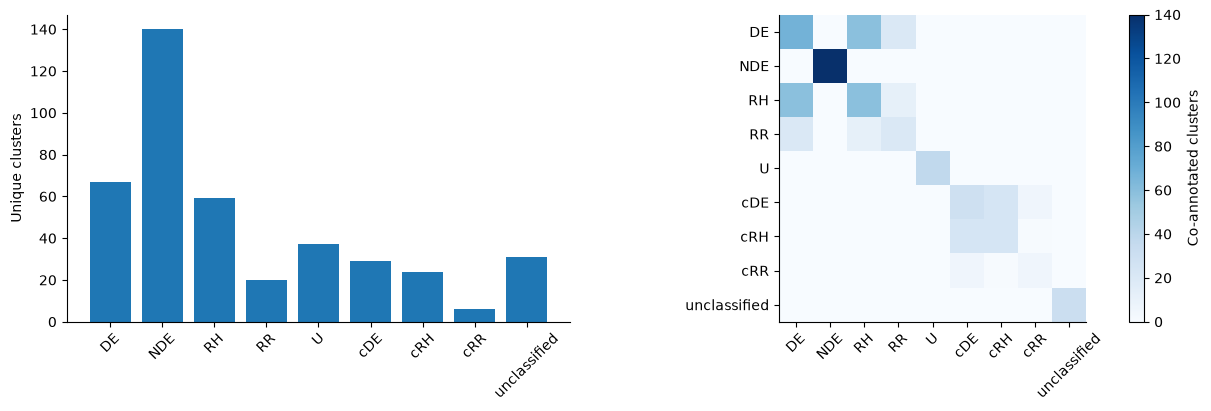

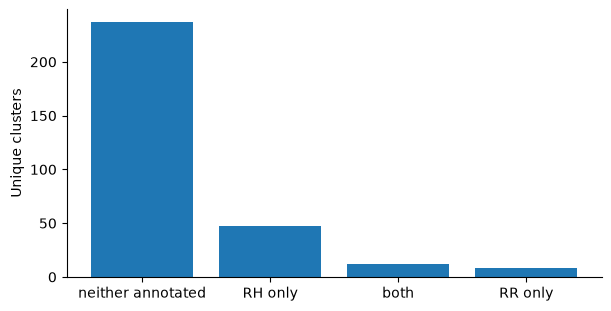

,annotation,clusters,radio,xray,optical
0,DE,67,67,58,67
1,NDE,140,140,27,111
2,RH,59,59,51,59
3,RR,20,20,17,20
4,U,37,37,15,37
5,cDE,29,29,0,28
6,cRH,24,24,0,23
7,cRR,6,6,0,6
8,unclassified,31,31,15,30


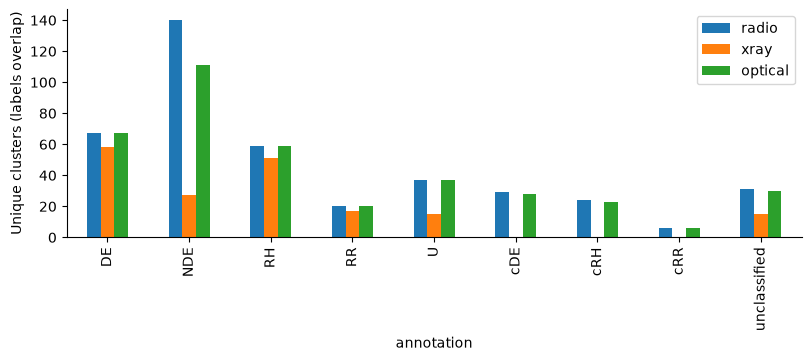

In [7]:
targets, tasks = da.classification_tables(records)
report.table("per_cluster_task_targets", targets)
display(report.table("classification_tasks", tasks))
matrix = da.label_matrix(clusters)
frequencies = matrix.sum().rename("clusters").rename_axis("annotation").reset_index()
display(report.table("annotation_distribution", frequencies))
cooccurrence = matrix.T @ matrix
report.table("label_cooccurrence", cooccurrence.rename_axis("annotation").reset_index())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(frequencies.annotation, frequencies.clusters); axes[0].set_ylabel("Unique clusters"); axes[0].tick_params(axis="x", rotation=45)
im = axes[1].imshow(cooccurrence, cmap="Blues")
axes[1].set_xticks(range(len(matrix.columns)), matrix.columns, rotation=45)
axes[1].set_yticks(range(len(matrix.columns)), matrix.columns); fig.colorbar(im, ax=axes[1], label="Co-annotated clusters")
report.figure("annotation_frequencies_and_overlap", fig)
rr = matrix.get("RR", pd.Series(0, index=clusters.index)).astype(bool)
rh = matrix.get("RH", pd.Series(0, index=clusters.index)).astype(bool)
combinations = pd.Series(np.select([rr & rh, rr, rh], ["both", "RR only", "RH only"], default="neither annotated"))
combo_table = combinations.value_counts().rename_axis("confirmed_directory_combination").reset_index(name="clusters")
report.table("rr_rh_original_combinations", combo_table)
fig, ax = plt.subplots(figsize=(6, 3)); ax.bar(combo_table.iloc[:, 0], combo_table.clusters); ax.set_ylabel("Unique clusters")
report.figure("rr_rh_combinations", fig)
label_availability = pd.DataFrame([dict(annotation=label, clusters=int(matrix[label].sum()),
    **{m: int((matrix[label].eq(1) & clusters[m]).sum()) for m in da.MODALITIES}) for label in matrix])
display(report.table("labels_by_modality", label_availability))
fig, ax = plt.subplots(figsize=(8, 3.5))
label_availability.set_index("annotation")[list(da.MODALITIES)].plot.bar(ax=ax)
ax.set_ylabel("Unique clusters (labels overlap)")
report.figure("labels_by_modality", fig)

## 7 — Preprocessing analysis

The actual `preprocess`, `centered_raw_window`, `block_average` and `normalize` functions are used. The reduction factor is the largest power of two that fits the requested size. This pipeline crops and block-averages; it does not perform an arbitrary image resize. X-ray is bilinearly reprojected before downsampling. No training caches are written.

Radio and X-ray normalization uses per-image 30th/99th percentiles and an asinh stretch (alpha=10). These are not training-set population statistics. The table compares reduced linear values and normalized valid-pixel statistics; original statistics are available in the observation table. Missing X-ray pixels are masked for statistics even though normalized tensors encode them as zero alongside a validity channel. Gallery radio images are display-stretched independently, so colors do not imply equal physical surface brightness across clusters.

Geometry uses the existing synchronized rotation/flip function. Examples are variants of one cluster. Configured zoom affects the virtual count in Section 1; this figure illustrates baseline rotation/flip. Noise and mixup are training operations and are not applied to observational statistics.

  'degree' -> 'deg',
  'degree' -> 'deg'. [astropy.wcs.wcs]


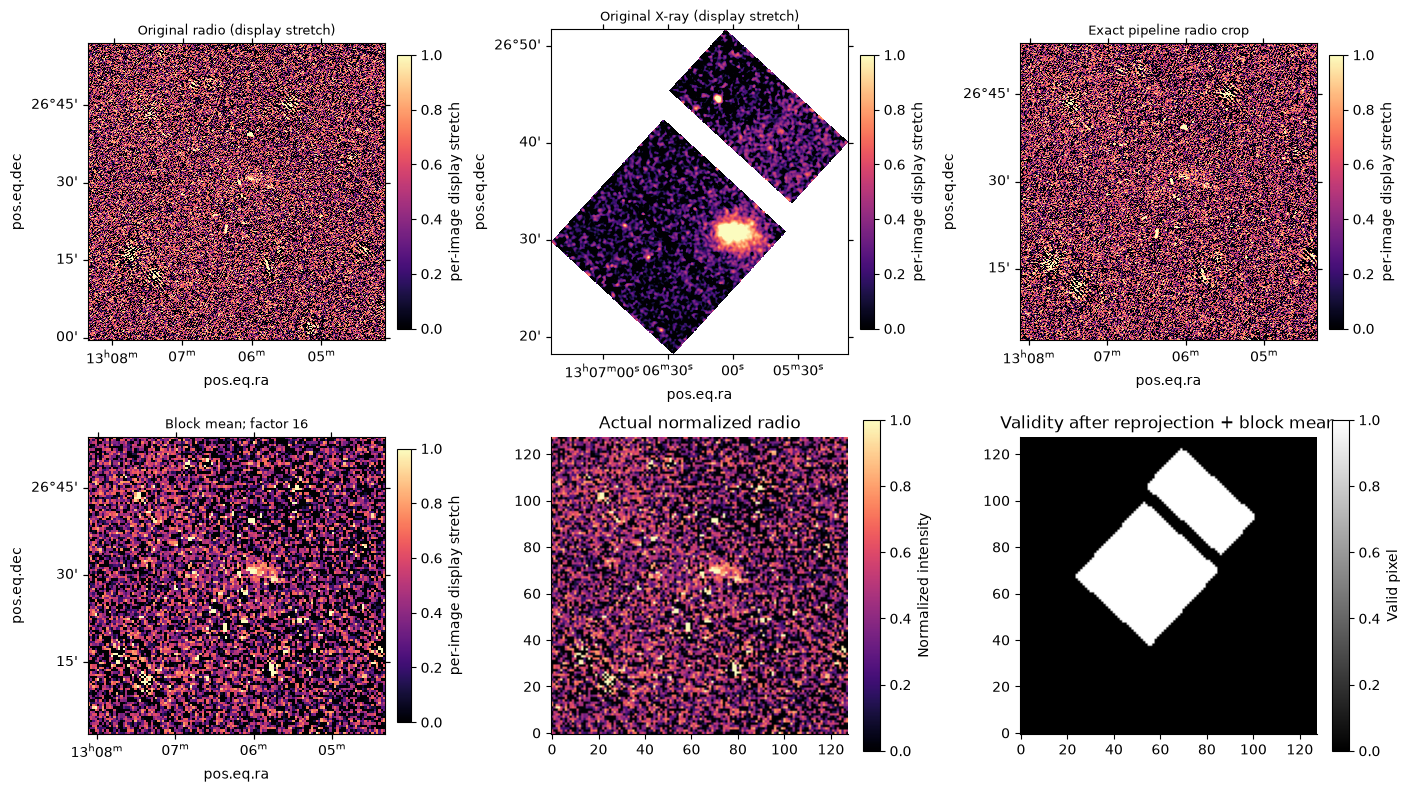

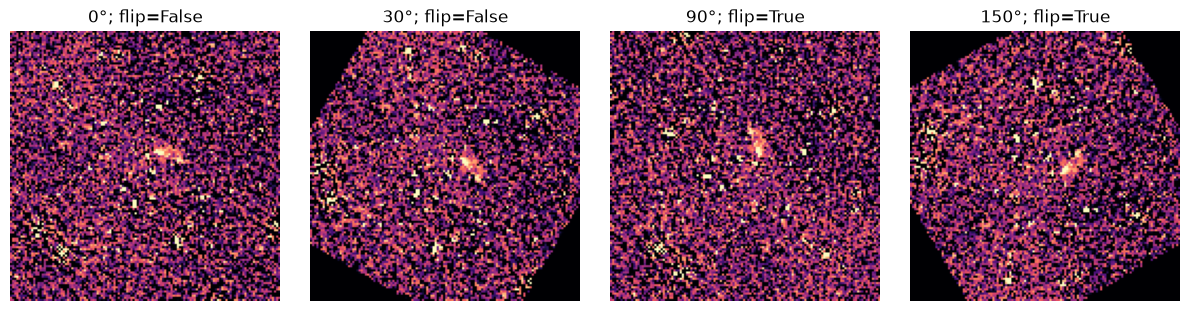

,cluster_id,status,factor,coverage,raw_reduced_finite_fraction,raw_reduced_median,raw_reduced_p99,raw_normalized_finite_fraction,raw_normalized_median,raw_normalized_p99,chandra_reduced_finite_fraction,chandra_reduced_median,chandra_reduced_p99,chandra_normalized_finite_fraction,chandra_normalized_median,chandra_normalized_p99
0,PSZ2G023.17+86.71,ok,16,0.180420,1.0,1.224798e-06,0.000147,1.0,0.289155,0.997951,1.0,-0.001383,0.026680,1.0,0.107746,0.998847
1,PSZ2G031.93+78.71,ok,16,0.150269,1.0,-7.504612e-08,0.000228,1.0,0.223210,0.998651,1.0,-0.000100,0.126916,1.0,0.021632,0.998550
2,PSZ2G033.81+77.18,ok,16,0.182068,1.0,9.931608e-07,0.000235,1.0,0.242537,0.998695,1.0,0.004480,1.054568,1.0,0.007375,0.998636
3,PSZ2G040.58+77.12,ok,16,0.150452,1.0,2.859228e-06,0.000187,1.0,0.300675,0.998387,1.0,0.000580,0.088465,1.0,0.057814,0.995437
4,PSZ2G045.13+67.78,ok,16,NaN,1.0,2.232916e-06,0.000116,1.0,0.348531,0.997461,NaN,NaN,NaN,NaN,NaN,NaN
5,PSZ2G045.87+57.70,ok,16,NaN,1.0,1.035488e-06,0.000134,1.0,0.334390,0.997804,NaN,NaN,NaN,NaN,NaN,NaN
6,PSZ2G046.88+56.48,ok,8,0.498840,1.0,7.815911e-06,0.000456,1.0,0.195453,0.997984,1.0,0.004960,0.064198,1.0,0.129071,0.999468
7,PSZ2G048.10+57.16,ok,16,0.148438,1.0,1.044202e-06,0.000191,1.0,0.225654,0.998385,1.0,0.000666,0.049020,1.0,0.139906,0.999986
8,PSZ2G048.75+53.18,ok,16,0.147644,1.0,1.704820e-06,0.000194,1.0,0.269667,0.998432,1.0,-0.000475,0.110005,1.0,0.033672,0.997620
9,PSZ2G049.18+65.05,ok,8,0.482178,1.0,1.880654e-06,0.000204,1.0,0.272646,0.998515,1.0,-0.000032,0.030462,1.0,0.256843,0.999986


In [8]:
da.preprocessing_example(records, config, report)
comparison_columns = [c for c in alignment if c.endswith(("median", "p99", "finite_fraction")) or c in ("cluster_id", "coverage", "factor", "status")]
display(report.table("preprocessing_comparison", alignment[comparison_columns]).head(12))

## 8 — Dataset quality and potential biases

Confirmed source problems are distinguished from potential issues requiring inspection. Identical duplicate files across annotation folders are expected membership copies. Extreme size/intensity flags use a conservative 3-IQR rule within modality and unit; they are not automatic exclusions. Poor reduced-grid coverage uses the JSON threshold. Non-finite pixels may represent legitimate survey boundaries.

No rows are silently removed from the population. The optical and X-ray subsets may reflect observational targeting; label availability and redshift summaries quantify some differences, not selection probabilities. Contour differences may be physical: this audit does not infer misalignment from different emission peaks. Header/WCS warnings and low/no overlap are inspection leads. No physical cluster quantities are derived from an assumed cosmology.

In [9]:
diagnostics = da.diagnostic_table(clusters, observations, alignment, discovery_issues, config)
display(report.table("diagnostics", diagnostics))
quality_summary = diagnostics.groupby(["status", "issue"]).cluster_id.nunique().rename("clusters").reset_index()
display(report.table("diagnostic_summary", quality_summary))

,cluster_id,issue,status
0,PSZ2G023.17+86.71,radio: 2 source copies (identical),confirmed
1,PSZ2G023.17+86.71,xray: 2 source copies (identical),confirmed
2,PSZ2G031.93+78.71,radio: 2 source copies (identical),confirmed
3,PSZ2G031.93+78.71,xray: 2 source copies (identical),confirmed
4,PSZ2G040.58+77.12,radio: 2 source copies (identical),confirmed
...,...,...,...
1340,PSZ2G187.74+20.66,"radio: extreme p99_minus_p01 (3 IQR rule, with...",potential — manual inspection
1341,PSZ2G056.77+36.32,"xray: extreme p99_minus_p01 (3 IQR rule, withi...",potential — manual inspection
1342,PSZ2G057.92+27.64,"xray: extreme p99_minus_p01 (3 IQR rule, withi...",potential — manual inspection
1343,PSZ2G033.81+77.18,"xray: extreme p99_minus_p01 (3 IQR rule, withi...",potential — manual inspection


,status,issue,clusters
0,confirmed,radio: 2 source copies (identical),83
1,confirmed,radio: 3 source copies (identical),13
2,confirmed,xray: 2 source copies (identical),48
3,confirmed,xray: 3 source copies (identical),10
4,confirmed,xray: non-finite pixels (may be intended footp...,103
...,...,...,...
77,potential — manual inspection,"optical: extreme p99_minus_p01 (3 IQR rule, wi...",15
78,potential — manual inspection,"radio: extreme p99_minus_p01 (3 IQR rule, with...",10
79,potential — manual inspection,"radio: extreme pixels (3 IQR rule, within unit...",1
80,potential — manual inspection,xray: FITS/WCS warning: 'unitfix' made the cha...,115


## 9 — Representative cluster gallery

Set `gallery_ids`, `gallery_categories` and `gallery_limit` in JSON to select objects; defaults choose one deterministic representative per category, preferring X-ray pairs. Selection is illustrative, not random. Radio, X-ray and optical panels use the same final radio WCS, aspect ratio and shape. X-ray contours use valid-image 80th/95th/99th percentiles; these are descriptive levels, not significance thresholds. Optical shows the first configured band. Missing observations are stated explicitly. Full-resolution PNG and vector PDF are exported when enabled.

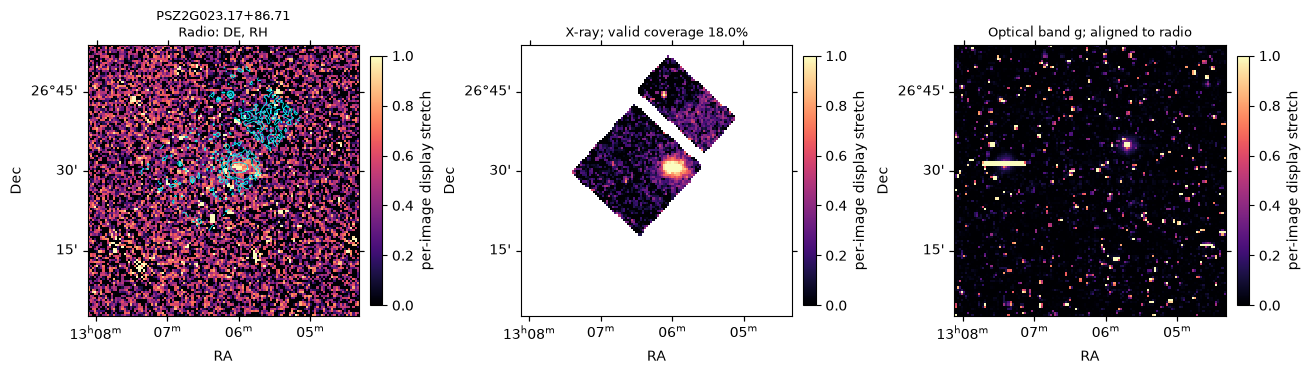

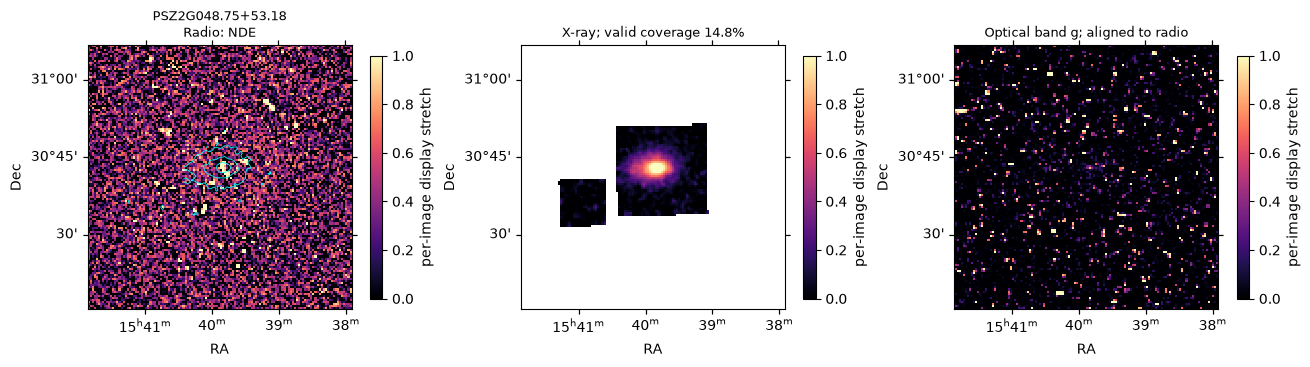

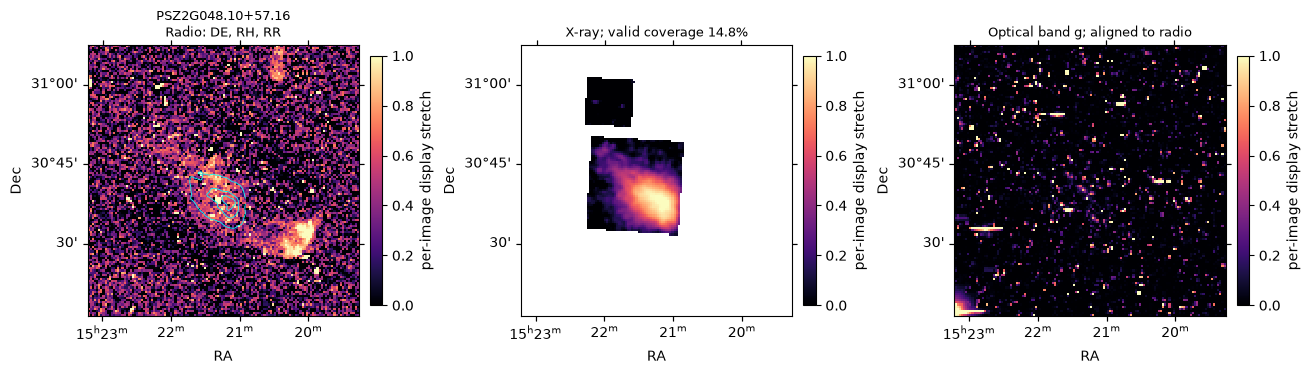

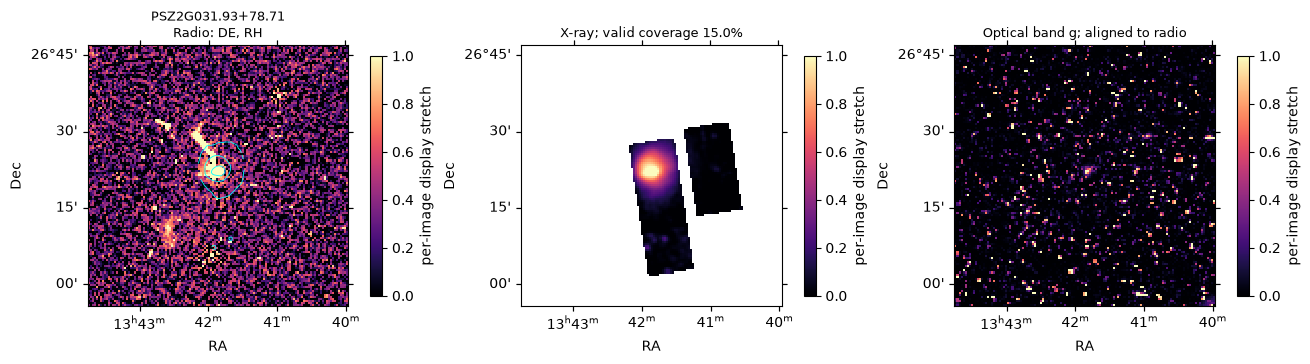

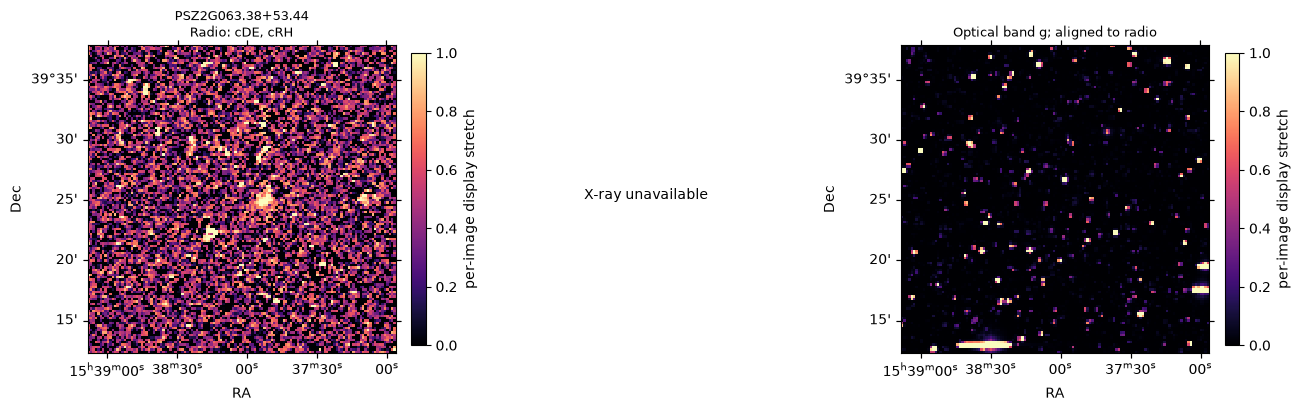

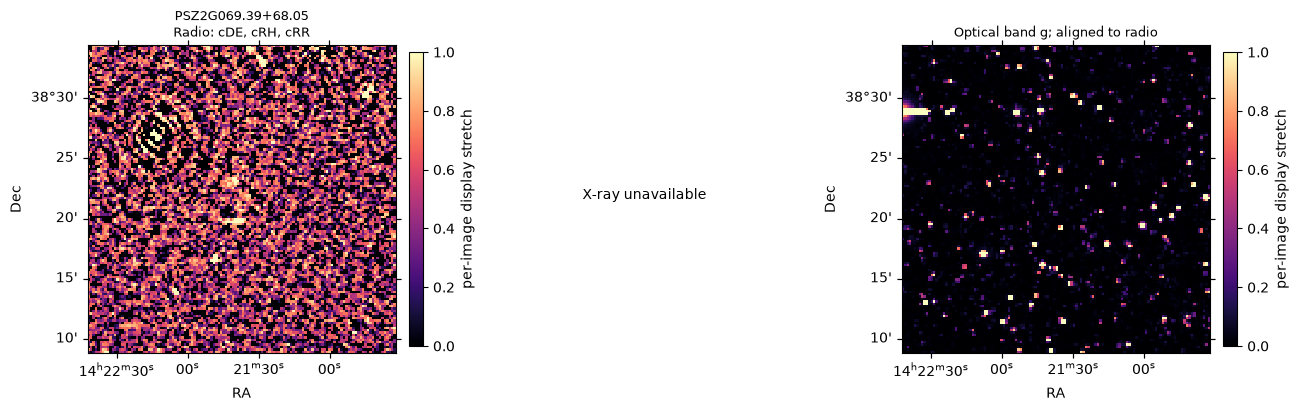

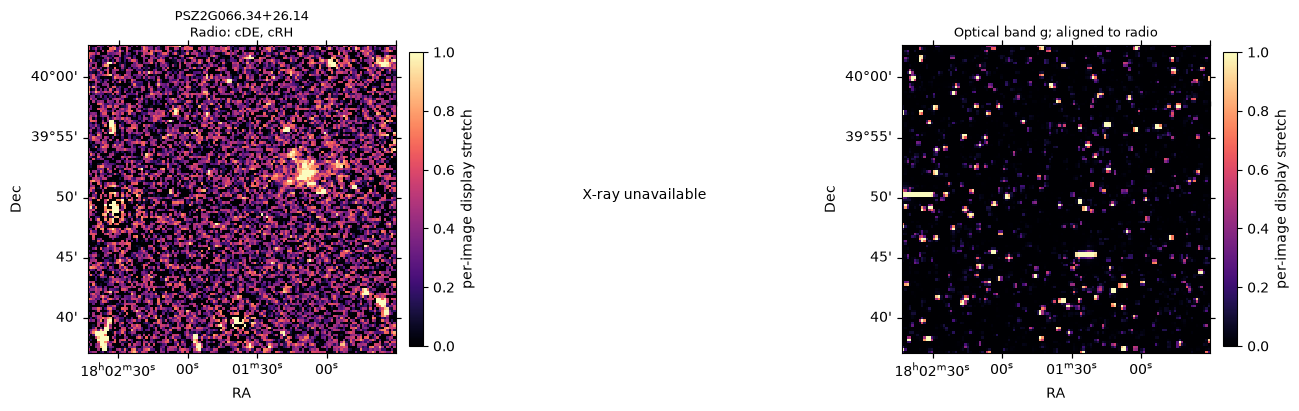

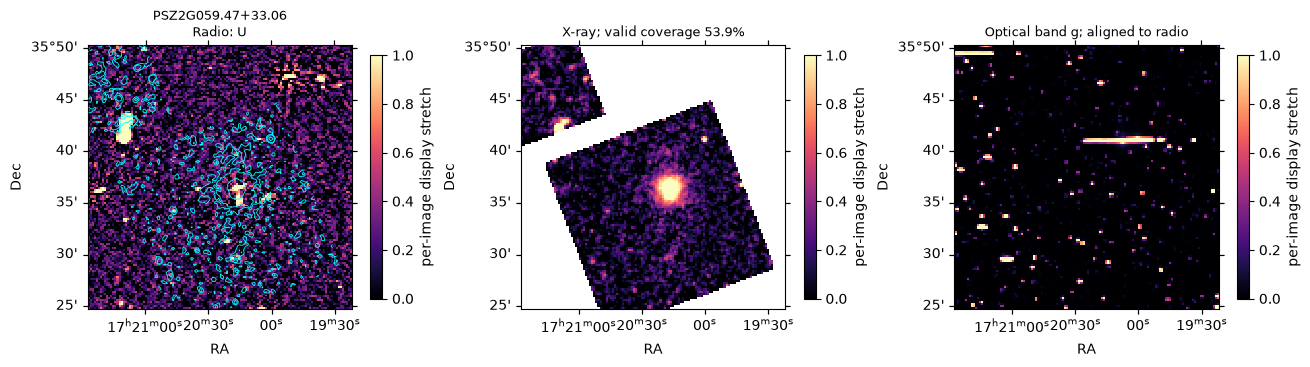

In [10]:
da.gallery(records, config, report)

## 10 — Report-ready summary

All values below are generated from the preceding tables. CSV and escaped LaTeX tables, source hashes, FITS warnings, configuration and package provenance support traceability. `summary.json` and the factual English text are intended as report starting points; retain the limitations below.

- Local availability and the catalogue union define this sample; no completeness correction is available.
- Original candidates remain uncertain even when a pipeline policy maps them to positive targets.
- File presence, readable images and valid aligned coverage are different quantities.
- Pixel quantiles are measured values in the reported units; display normalization removes absolute intensity meaning.
- Missing metadata, catalogue units and unverified registration cannot be recovered from this audit.
- Aligned finite support is not an exposure map or physical flux calibration.
- Train-scope optical normalization requires a defined training split and is intentionally not fitted here.

In [11]:
summary, dataset_text = da.finish(report, clusters, observations, tasks, diagnostics, alignment)
display(Markdown(dataset_text))
display(report.table("figure_index", pd.DataFrame({"figure": report.figures})))
display(report.tables["dataset_composition"])
display(report.tables["classification_tasks"])
print("Exports:", config["output_dir"] if config["export"] else "disabled")

The configured catalogue and observational directories contain 304 unique cluster identifiers. Unambiguous radio, X-ray and optical source files are available for 304, 115 and 273 clusters, respectively. Original directory annotations other than 'unclassified' are present for 273 clusters. The audit identified 0 invalid or unreadable products. These are pre-split counts; augmented variants are not independent clusters. Original annotations and pipeline targets are tabulated separately, including candidate-policy sensitivity. X-ray validity describes finite support after reprojection and block averaging, not physical zero emission. The sample is defined by the configured catalogue and local files and is not asserted to be survey-complete.

,figure
0,modality_intersections
1,radio_geometry
2,radio_beams
3,radio_intensities_bf55e924
4,xray_geometry
5,xray_exposure
6,xray_intensities_0cd7899f
7,xray_valid_coverage
8,angular_coverage_comparison
9,optical_geometry


,Property,Value
0,Unique cluster IDs,304
1,Original annotations (excluding unclassified),273
2,radio selected file,304
3,xray selected file,115
4,optical selected file,273
5,Radio + X-ray,115
6,All three,115
7,Physical FITS copies,869
8,Unique products,692
9,Invalid/unreadable paths,0


,task,candidate_policy,target,eligible,excluded,masked,positives,negatives,positive_fraction
0,de_nde,ignore,NDE (target 1; DE is 0),207,97,0,140,67,0.676329
1,de_nde,positive,NDE (target 1; DE is 0),207,97,0,140,67,0.676329
2,rh_binary,ignore,RH,207,97,0,59,148,0.285024
3,rh_binary,positive,RH,236,68,0,83,153,0.351695
4,rr_binary,ignore,RR,207,97,0,20,187,0.096618
5,rr_binary,positive,RR,236,68,0,26,210,0.110169
6,rr_rh,ignore,RR,236,68,6,20,210,0.086957
7,rr_rh,ignore,RH,236,68,24,59,153,0.278302
8,rr_rh,positive,RR,236,68,0,26,210,0.110169
9,rr_rh,positive,RH,236,68,0,83,153,0.351695


Exports: /Users/antoinegdrn/PH_Project_I/outputs/dataset_analysis
